# Tuần 3 · Đánh giá cuối

Đánh giá offline khả năng dự đoán nhãn `Revenue=True` từ dữ liệu tổng hợp theo phiên. Chọn mô hình theo AP trung bình trên validation tuần 2, chọn ngưỡng trên train và đánh giá cấu hình đã chốt trên tập test của tuần 1.

## 1. Kiểm tra dữ liệu và lấy tập train

In [1]:
%matplotlib inline
import json
from hashlib import sha256
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

csv_path = Path("data/online_shoppers_intention.csv")
split = json.loads(Path("data/split_indices.json").read_text(encoding="utf-8"))
if sha256(csv_path.read_bytes()).hexdigest() != split["csv_sha256"]:
    raise ValueError("CSV đã thay đổi so với split tuần 1.")

df = pd.read_csv(csv_path)
train_indices = split["train_indices"]
test_indices = split["test_indices"]
all_indices = train_indices + test_indices
if (
    not train_indices or not test_indices
    or any(type(index) is not int for index in all_indices)
    or len(all_indices) != len(df)
    or split["n_rows"] != len(df)
    or set(all_indices) != set(df.index)
):
    raise ValueError("Split phải phủ đủ dữ liệu và mỗi vị trí xuất hiện đúng một lần.")

train = df.iloc[train_indices]
X_train = train.drop(columns=["Revenue", "PageValues"])
y_train = train["Revenue"]
print(f"Train: {len(train):,} phiên, {X_train.shape[1]} feature.")

Train: 9,864 phiên, 16 feature.


## 2. Chốt mô hình và ngưỡng từ train

Lấy cấu hình có AP trung bình cao nhất trong bảng validation tuần 2. Giữ cấu hình và preprocessing đã so sánh, với one-hot encoding cho 7 cột phân loại và giữ nguyên thang số. Tạo xác suất out-of-fold (OOF) với cùng 5 fold. Mỗi phiên train có xác suất từ một pipeline chưa fit trên phiên đó.

Chọn ngưỡng tối đa hóa F1 của lớp mua trên toàn bộ dự đoán OOF. Khi có nhiều ngưỡng đạt cùng F1 cao nhất, dùng ngưỡng lớn nhất. Giữ nguyên ngưỡng đầy đủ khi dự đoán. AP và ROC-AUC sử dụng xác suất gốc.

In [2]:
validation = pd.read_csv("reports/validation_scores.csv")
winner = validation.loc[validation["mean_average_precision"].idxmax()]
if winner["model"] != "Random Forest" or winner["scale_numeric"]:
    raise ValueError("Kết quả validation đã đổi. Hãy kiểm tra lại cấu hình pipeline.")

categorical_columns = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend",
]
numeric_columns = [col for col in X_train if col not in categorical_columns]
preprocessing = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     categorical_columns),
    ("numeric", "passthrough", numeric_columns),
])
params = json.loads(winner["parameters"])
pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("classifier", RandomForestClassifier(**params)),
])

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_scores = cross_val_predict(
    pipeline, X_train, y_train, cv=folds, method="predict_proba", n_jobs=1,
)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_scores)
# Điểm cuối của đường PR không tương ứng với một ngưỡng.
p, r = precision[:-1], recall[:-1]
f1_values = np.divide(2 * p * r, p + r, out=np.zeros_like(p), where=(p + r) > 0)
best = np.flatnonzero(f1_values == f1_values.max())[-1]
threshold = float(thresholds[best])

print(f"{winner['model']} | AP validation: {winner['mean_average_precision']:.4f}")
print({key: params[key] for key in (
    "n_estimators", "max_depth", "min_samples_leaf", "random_state", "class_weight"
)})
print(f"Ngưỡng đã chốt: {threshold!r}")
print(f"F1 OOF tại ngưỡng đã chốt: {f1_values[best]:.4f}")
print(f"F1 OOF tại ngưỡng 0,5: {f1_score(y_train, oof_scores >= 0.5):.4f}")

Random Forest | AP validation: 0.3762
{'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 5, 'random_state': 42, 'class_weight': None}
Ngưỡng đã chốt: 0.20964924233624288
F1 OOF tại ngưỡng đã chốt: 0.4239
F1 OOF tại ngưỡng 0,5: 0.0405


## 3. Đánh giá cấu hình đã chốt trên test

,Điểm test
Average Precision,0.3542
ROC-AUC,0.7610
Precision (mua),0.3030
Recall (mua),0.5838
F1 (mua),0.3989


TN=1571, FP=513, FN=159, TP=223 | tổng=2466


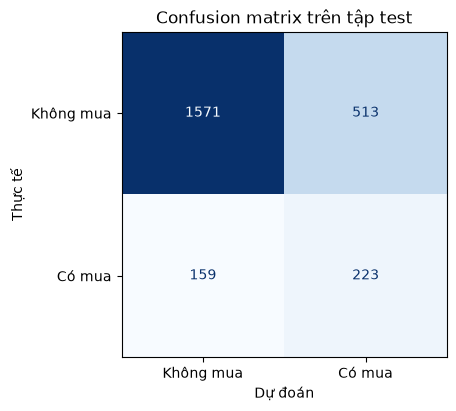

In [3]:
pipeline.fit(X_train, y_train)
test = df.iloc[test_indices]
X_test = test[X_train.columns]
y_test = test["Revenue"]
test_scores = pipeline.predict_proba(X_test)[:, 1]
y_pred = test_scores >= threshold

metrics = {
    "Average Precision": average_precision_score(y_test, test_scores),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
    "Precision (mua)": precision_score(y_test, y_pred),
    "Recall (mua)": recall_score(y_test, y_pred),
    "F1 (mua)": f1_score(y_test, y_pred),
}
display(pd.Series(metrics, name="Điểm test").to_frame().round(4))

matrix = confusion_matrix(y_test, y_pred, labels=[False, True])
tn, fp, fn, tp = matrix.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp} | tổng={matrix.sum()}")

fig, ax = plt.subplots(figsize=(5.4, 4), layout="constrained")
ConfusionMatrixDisplay(matrix, display_labels=["Không mua", "Có mua"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d"
)
ax.set(title="Confusion matrix trên tập test", xlabel="Dự đoán", ylabel="Thực tế")
plt.show()

## 4. Phân tích lỗi

So sánh các nhóm FN (bỏ sót phiên mua) và FP (báo nhầm phiên mua) với các nhóm cùng nhãn thực tế. Mỗi nhóm lỗi có thêm hai ví dụ mà mô hình cho điểm lệch xa ngưỡng nhất theo hướng dự đoán sai. Điểm dưới đây là xác suất đầu ra của mô hình. Các ví dụ mô tả lỗi trên tập test.

In [4]:
cases = pd.DataFrame({
    "Nhóm": np.select(
        [y_test & y_pred, y_test & ~y_pred, ~y_test & y_pred],
        ["TP", "FN", "FP"], default="TN",
    ),
    "Điểm mua": test_scores,
    "ProductRelated": X_test["ProductRelated"],
    "ProductRelated_Duration": X_test["ProductRelated_Duration"],
    "ExitRates": X_test["ExitRates"],
    "VisitorType": X_test["VisitorType"],
})
cases.index.name = "Vị trí dòng CSV (từ 0)"
feature_columns = ["Điểm mua", "ProductRelated", "ProductRelated_Duration", "ExitRates"]
display(cases.groupby("Nhóm")[feature_columns].median().round(4))
fn_examples = cases[cases["Nhóm"].eq("FN")].nsmallest(2, "Điểm mua")
fp_examples = cases[cases["Nhóm"].eq("FP")].nlargest(2, "Điểm mua")
display(pd.concat([fn_examples, fp_examples]).round(4))

,Điểm mua,ProductRelated,ProductRelated_Duration,ExitRates
Nhóm,,,,
FN,0.1526,18.0,603.7071,0.0286
FP,0.2628,35.0,1199.9167,0.0128
TN,0.0871,12.0,324.7692,0.0375
TP,0.3088,42.0,1460.9083,0.0116


,Nhóm,Điểm mua,ProductRelated,ProductRelated_Duration,ExitRates,VisitorType
Vị trí dòng CSV (từ 0),,,,,,
2392,FN,0.0180,3,127.0000,0.0667,Returning_Visitor
4407,FN,0.0187,19,421.6000,0.0772,Returning_Visitor
9576,FP,0.6187,337,11835.1039,0.0157,Returning_Visitor
8833,FP,0.5613,169,6920.9732,0.0168,Returning_Visitor


Kết quả mô tả hiệu năng offline trên một split của UCI. Dataset có mất cân bằng lớp, và CSV thiếu mã phiên để đối chiếu các dòng giống nhau. Feature là dữ liệu tổng hợp của phiên, do đó đánh giá này áp dụng cho bối cảnh dùng dữ liệu tổng hợp đã có. Xem diễn giải kết quả trong [báo cáo](reports/report.md).